In [4]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from torch.utils.data import TensorDataset, DataLoader, random_split

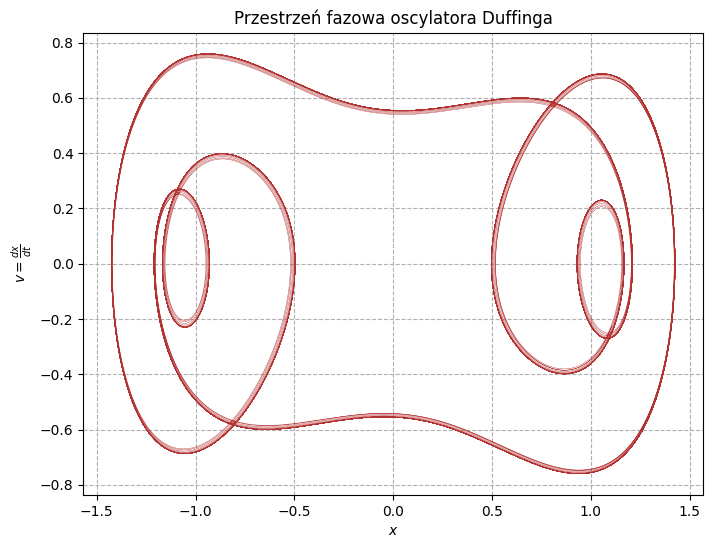

In [ ]:
#WIZUALIZACJA PRZESTRZENI FAZOWEJ

DELTA = 0.2
ALFA = -1.0
BETA = 1.0
GAMMA = 0.3
OMEGA = 1.2

def duffing(t, z):
    x, v = z
    dxdt = v
    dvdt = -DELTA*v - ALFA*x - BETA*x**3 + GAMMA*np.cos(OMEGA*t)
    return [dxdt, dvdt]

t_final = 1000  
t_eval = np.linspace(0, t_final, 100000)

x0 = 0.1
v0 = 0.0
z0 = [x0, v0]

sol = solve_ivp(duffing, [0, t_final], z0, t_eval=t_eval, rtol=1e-8, atol=1e-8)

x_val = sol.y[0]
v_val = sol.y[1]

cut = int(0.4 * len(x_val))

plt.figure(figsize=(8, 6))
plt.plot(x_val[cut:], v_val[cut:], color=(0.7, 0.2, 0.2), linewidth=0.3)
plt.xlabel("$x$")
plt.ylabel(r"$v = \frac{dx}{dt}$")
plt.title("Przestrzeń fazowa oscylatora Duffinga")
plt.grid(ls='--')
plt.show()

In [ ]:
#GLOBAL

NUM_SAMPLES = 5000
NUM_TIME_STEPS = 100
T_MAX = 20.0
t_eval = np.linspace(0, T_MAX, NUM_TIME_STEPS)

In [7]:
#GROUND TRUTH

def duffing_deriv(t, state, alpha, beta, delta, gamma, omega):
    x, v = state
    dxdt = v
    dvdt = gamma * np.cos(omega * t) - delta * v - alpha * x - beta * (x**3)
    return [dxdt, dvdt]

In [10]:
#DATASET GENERATION

def generate_data(num_samples):
    X_data = np.zeros((num_samples, 7))
    Y_data = np.zeros((num_samples, NUM_TIME_STEPS))
    
    for i in range(num_samples):
        alpha = np.random.uniform(-1.0, 1.0)
        beta = np.random.uniform(0.1, 1.0)
        delta = np.random.uniform(0.0, 0.5)
        gamma = np.random.uniform(0.0, 1.0)
        omega = np.random.uniform(0.5, 1.5)
        x0 = np.random.uniform(-2.0, 2.0)
        v0 = np.random.uniform(-2.0, 2.0)
        
        params = (alpha, beta, delta, gamma, omega)
        sol = solve_ivp(duffing_deriv, [0, T_MAX], [x0, v0], args=params, t_eval=t_eval)
        
        X_data[i] = [alpha, beta, delta, gamma, omega, x0, v0]
        Y_data[i] = sol.y[0]
        
    return torch.tensor(X_data, dtype=torch.float32), torch.tensor(Y_data, dtype=torch.float32)


In [ ]:
#NEURAL NETWORK

class DuffingNet(nn.Module):
    def __init__(self, input_dim=7, output_dim=100):
        super(DuffingNet, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.GELU(),
            nn.Linear(64, 128),
            nn.GELU(),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Linear(128, output_dim)
        )

    def forward(self, x):
        return self.net(x)

In [14]:
X, Y = generate_data(NUM_SAMPLES)
dataset = TensorDataset(X, Y)

train_size = 4000
test_size = 1000
train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

model = DuffingNet()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 500
for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        predictions = model(batch_x)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            predictions = model(batch_x)
            loss = criterion(predictions, batch_y)
            test_loss += loss.item()
            
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss/len(train_loader):.4f} | Test Loss: {test_loss/len(test_loader):.4f}")

Epoch 10/500 | Train Loss: 0.6137 | Test Loss: 0.6642
Epoch 20/500 | Train Loss: 0.4839 | Test Loss: 0.5402
Epoch 30/500 | Train Loss: 0.4048 | Test Loss: 0.4904
Epoch 40/500 | Train Loss: 0.3555 | Test Loss: 0.4674
Epoch 50/500 | Train Loss: 0.3137 | Test Loss: 0.4474
Epoch 60/500 | Train Loss: 0.2900 | Test Loss: 0.4479
Epoch 70/500 | Train Loss: 0.2585 | Test Loss: 0.4465
Epoch 80/500 | Train Loss: 0.2379 | Test Loss: 0.4252
Epoch 90/500 | Train Loss: 0.2218 | Test Loss: 0.4259
Epoch 100/500 | Train Loss: 0.2072 | Test Loss: 0.4335
Epoch 110/500 | Train Loss: 0.1915 | Test Loss: 0.4333
Epoch 120/500 | Train Loss: 0.1788 | Test Loss: 0.4431
Epoch 130/500 | Train Loss: 0.1685 | Test Loss: 0.4568
Epoch 140/500 | Train Loss: 0.1592 | Test Loss: 0.4493
Epoch 150/500 | Train Loss: 0.1528 | Test Loss: 0.4717
Epoch 160/500 | Train Loss: 0.1439 | Test Loss: 0.4666
Epoch 170/500 | Train Loss: 0.1376 | Test Loss: 0.4616
Epoch 180/500 | Train Loss: 0.1310 | Test Loss: 0.4732
Epoch 190/500 | Tra

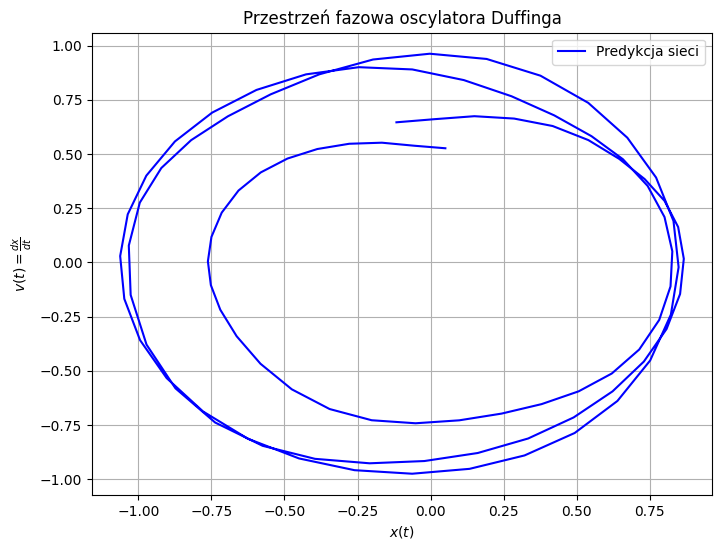

In [18]:
def plot_phase_space(model, sample_params, t_eval):
    model.eval()
    with torch.no_grad():
        
        x_pred = model(sample_params).numpy().flatten()
    
    dt = t_eval[1] - t_eval[0]
    
    v_pred = np.gradient(x_pred, dt)
    
    plt.figure(figsize=(8, 6))
    plt.plot(x_pred, v_pred, label="Predykcja sieci", color='blue')
    plt.title("Przestrzeń fazowa oscylatora Duffinga")
    plt.xlabel(r"$ x(t)$")
    plt.ylabel(r"$ v(t) = \frac{dx}{dt}$")
    plt.grid(True)
    plt.legend()
    plt.show()

sample_idx = 0
sample_x, sample_y = test_dataset[sample_idx]
plot_phase_space(model, sample_x.unsqueeze(0), t_eval)

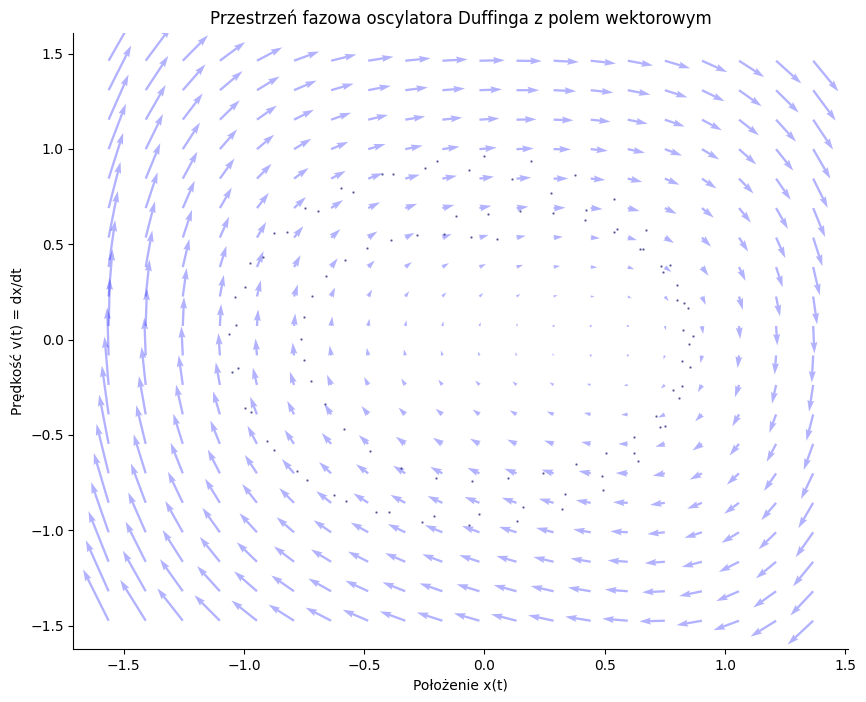

In [22]:
import numpy as np
import matplotlib.pyplot as plt

def plot_attractor_with_vector_field(model, sample_params, t_eval):
    model.eval()
    
    params = sample_params.numpy().flatten()
    alpha, beta, delta, gamma, omega, _, _ = params

    with torch.no_grad():
        x_pred = model(sample_params).numpy().flatten()
    
    dt = t_eval[1] - t_eval[0]
    v_pred = np.gradient(x_pred, dt)
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    x_min, x_max = x_pred.min() - 0.5, x_pred.max() + 0.5
    v_min, v_max = v_pred.min() - 0.5, v_pred.max() + 0.5
    
    X_grid, V_grid = np.meshgrid(np.linspace(x_min, x_max, 20), 
                                 np.linspace(v_min, v_max, 20))
    
    t_snapshot = 0 
    U = V_grid
    V = gamma * np.cos(omega * t_snapshot) - delta * V_grid - alpha * X_grid - beta * (X_grid**3)
    
    ax.quiver(X_grid, V_grid, U, V, color='blue', alpha=0.3, angles='xy', scale_units='xy')
    
    ax.scatter(x_pred, v_pred, s=0.5, color='midnightblue', alpha=0.6, label='Punkty trajektorii')
    
    ax.set_title("Przestrzeń fazowa oscylatora Duffinga z polem wektorowym")
    ax.set_xlabel("Położenie x(t)")
    ax.set_ylabel("Prędkość v(t) = dx/dt")
    ax.grid(False)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    plt.show()


plot_attractor_with_vector_field(model, sample_x.unsqueeze(0), t_eval)